# Statistical Simulation with NumPy Arrays

> This page is adapted from [Brett, Rush, Adhikari, Denero and Wagner (2023)](https://odsti.github.io/cfd-textbook/leaping_ahead.html). See the [license](https://github.com/pxr687/Intro_Comp_Programming/blob/main/license.md) page for more information

We now have everything we need for a solution for the [three girls
problem](https://pxr687.github.io/Intro_Comp_Programming/1_04_A_Simple_Problem.html).

Remember that this simple probability problem is:

> Imagine a family with four children. What is the probability that the family will have three girls?

We have more of the building blocks we need to give an accurate answer, using computer simulation.

Remember that *simulation* is a noun which means:

> A simulation is the representation of a real-world process, system, or situation over time using a model, often using a computer.

In [2]:
# Load the Numpy package, and rename to "np".
import numpy as np

We are going to simulate 10000 families, each with four children. This will let us calculate the probability of having three girls in one family.

Call one family *one trial*.  Each *trial* involves the simulation of four
children.

Here we put together what we have up until now.  We are creating a Numpy array that has 10000 values, each of which is 0:

In [3]:
# Make an array of zeros to store the counts for each of the 10000 families.
counts = np.zeros(10000)
counts

array([0., 0., 0., ..., 0., 0., 0.], shape=(10000,))

`counts` has 10000 elements. When we have finished, each of these 10000 values
will be the number of girls in one simulated family.

From [boolean arrays](boolean_arrays), here is how we make an array that
simulates a family of four children, and count the number of girls.

In [4]:
# Make an array of four random choices from 0 or 1.
# 1 means a girl.
children = np.random.choice(["BOY", "GIRL"], size=4)
print(children)
# Add up the integers to count the number of girls.
count = np.sum(children == "GIRL")
count

['BOY' 'GIRL' 'BOY' 'GIRL']


np.int64(2)

We can store this count at the beginning of our 10000 counts:

In [5]:
# Store the count as the first value in the counts array.
counts[0] = count
# Show the first 10 values
counts[:10]

array([2., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

Here that is again, in a single cell:

In [6]:
# Our first simulated family
children = np.random.choice(["BOY", "GIRL"], size=4)
counts[0] = np.sum(children == "GIRL")
counts[:10]

array([1., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

To add another family, we just repeat the same, but storing the result as the
*second* value in the `counts` array:

In [7]:
# Our second simulated family
children = np.random.choice(["BOY", "GIRL"], size=4)
counts[1] = np.sum(children == "GIRL")
counts[:10]

array([1., 3., 0., 0., 0., 0., 0., 0., 0., 0.])

Notice that the only thing that changed is that we stored the value at position (offset) 1 instead of position (offset) 0.

Obviously this is getting a bit boring and repetitive. Surely we can do
better.

Yes indeed, we can use a *`for` loop*.   You will recognize nearly all the code below, from the single trials we did above.  The new thing is the *`for` loop*, that tells Python to repeat the indented steps 10000 times.

In [8]:
# Reset the counts array to 10000 zeros.
counts = np.zeros(10_000)

# Repeat the indented stuff 10000 times.
for i in np.arange(10_000):
    # The procedure for one family.
    children = np.random.choice(["BOY", "GIRL"], size=4)
    count = np.sum(children == "GIRL")
    # Store the count at position i in the counts array.
    counts[i] = count
# Show the first 10 counts
counts[:10]

array([2., 1., 2., 4., 3., 3., 0., 1., 3., 1.])

Now we have a count of the number of girls, from 10000 simulated families:

In [9]:
len(counts)

10000

We use [Boolean arrays](boolean_arrays) to make an array of 10000 elements, where each element is True if the corresponding element in `counts` was equal to 3, and False otherwise.

In [10]:
# The Boolean array
has_3_girls = counts == 3
has_3_girls

array([False, False, False, ..., False, False, False], shape=(10000,))

`np.count_nonzero` counts the number of True values (and therefore, the number of `counts` equal to 3).

In [11]:
# Number of counts values equal to 3.
n_3_girls = np.count_nonzero(has_3_girls)
n_3_girls

np.int64(2444)

Finally we estimate the probability by dividing the number of times we saw 3 by
the number of trials:

In [12]:
# Estimate probability of 3 girls.
n_3_girls / 10000

np.float64(0.2444)

At the moment the probability is a decimal number; we can convert it to a percentage (%) by multiplying it by 100:

In [13]:
# Estimate probability of 3 girls (as a percentage).
n_3_girls / 10000 * 100

np.float64(24.44)

So that's around a 25% probability of having three girls in a family with four children...

## The whole thing

Here then is the whole solution to three girl problem.

It is made from the combination of the code in the cells above.

In [12]:
# Reset the counts array to 10000 zeros.
counts = np.zeros(10000)

# Repeat the indented stuff 10000 times.
for i in np.arange(10000):
    # The procedure for one family.
    children = np.random.choice(["BOY", "GIRL"], size=4)
    count = np.sum(children == "GIRL")
    # Store the count at position i in the counts array.
    counts[i] = count

# True where counts has the value 3, False otherwise.
has_3_girls = counts == 3

# Number of counts values equal to 3.
n_3_girls = np.count_nonzero(has_3_girls)

# Estimate and show probability of 3 girls.
n_3_girls / 10000

np.float64(0.2386)

## A Quick Introduction to Data Visualization in Python

The number that was output from the last code cell is a probability.

Humans are very visual creatures. Sometimes patterns in data can be easily to see when we put them on a graph.

To do this, we will use the [matplotlib](https://matplotlib.org/) visualization library.

This library is basic, but very flexible.

To import the functions from it, we use this import statement:

`import matplotlib.pyplot as plt`

We will plot the `counts` array as a [histogram](https://en.wikipedia.org/wiki/Histogram). To do this we use the helpfully named `plt.hist()` function. The other functions in the cell make the graph easier to read/look nicer:

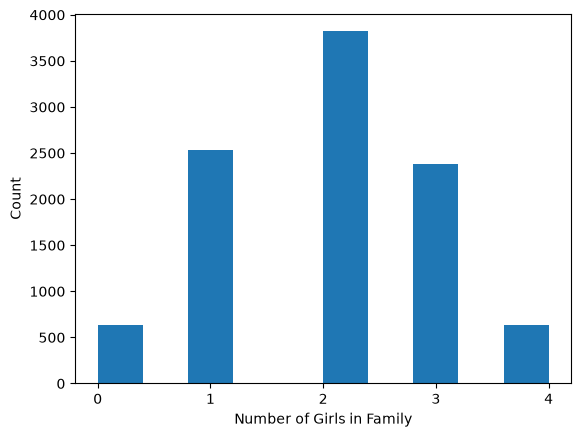

In [26]:
# Import `matplotlib`.
import matplotlib.pyplot as plt

# Make a histogram, and add labels to the x-axis and y-axis.
plt.hist(counts)
plt.xlabel('Number of Girls in Family')
plt.ylabel('Count')
# Make the x-axis show only integer values.
plt.xticks(np.arange(counts.min(), 
                     counts.max()+1));

Each bar on this histogram show us the *number* of families, in our simulation, who had a specific number of girls.

To get the probabiliy, we can look at the height of a bar and divide it by the number of families in the simulation.

We can do this using the `weights =` argument of the `plt.hist()` function:

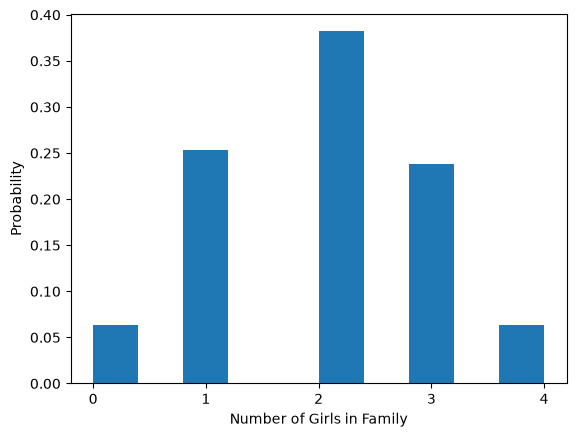

In [27]:
# Make a histogram, and add labels to the x-axis and y-axis (show probabilities instead of counts).
weights = np.ones_like(counts)/len(counts)
plt.hist(counts, weights=weights)
plt.xlabel('Number of Girls in Family')
plt.ylabel('Probability')
# Make the x-axis show only integer values.
plt.xticks(np.arange(counts.min(), 
                     counts.max()+1));

Look at the y-axis height of the bar for 3 girls you can see it is around 0.25 (which means 25% probability).

In fact, it is exactly the same probability that we got from our simulation!:

In [28]:
n_3_girls / 10000

np.float64(0.2386)

Remember, we can multiply this by 100 to show it as a percentage:

In [29]:
n_3_girls / 10000 * 100

np.float64(23.86)

So to answer our three girls problem using simulation, the probability of a family of 4 having 3 girls is around 25%.

## Exercise - Statistical Simulation

Now it's over to you to perform your own statistical simulation...

Click [here 🚀](https://mybinder.org/v2/gh/pxr687/Intro_Comp_Programming/main?urlpath=tree/exercise_4h_simulation_exercise.ipynb) to launch the exercise on Binder.